# Figure S3 — movement speed and ensemble activity

This plot-only notebook reads the compact Figure S3 source tables, recreates panel A, and performs the paired mouse-level analyses used for panels B and C. It does not read raw recordings or redefine preprocessing functions.

**Cohort and caption provenance warning.** The accepted plots explicitly exclude `W11`, leaving 10 WT mice in the OFT paired comparisons. Those plotted data contain **193 center-ON and 220 corner-ON neurons**. The final manuscript caption instead reports **203 center-ON and 226 corner-ON neurons** while also saying that 10 WT mice were used. Those caption counts correspond to the earlier 11-WT table. This notebook preserves the accepted 10-WT plotting cohort and reports the counts actually analyzed; it does not silently force the data to agree with the conflicting caption.

Within each temporal analysis, the six paired Wilcoxon tests (three assays × two genotypes) are corrected together using Benjamini–Hochberg FDR.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'pyproject.toml').is_file()
)
SOURCE = ROOT / 'data' / 'source_data' / 'figure_s03'
FIGURES = ROOT / 'results' / 'figures'
TABLES = ROOT / 'results' / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

WT_PLOT_COHORT = [f"W{index:02d}" for index in range(1, 11)]
RTT_PLOT_COHORT = [f"R{index:02d}" for index in range(1, 12)]
SELECTED_MICE = set(WT_PLOT_COHORT + RTT_PLOT_COHORT)

print('Repository root located from pyproject.toml.')
print(f'Accepted plot cohort: {len(WT_PLOT_COHORT)} WT and {len(RTT_PLOT_COHORT)} RTT mice')

Repository root located from pyproject.toml.
Accepted plot cohort: 10 WT and 11 RTT mice


## Ensemble transient rate versus movement speed

Each point is one 10-s interval. The two panels use the same 178 intervals pooled from 16 mice, as described in the final caption.

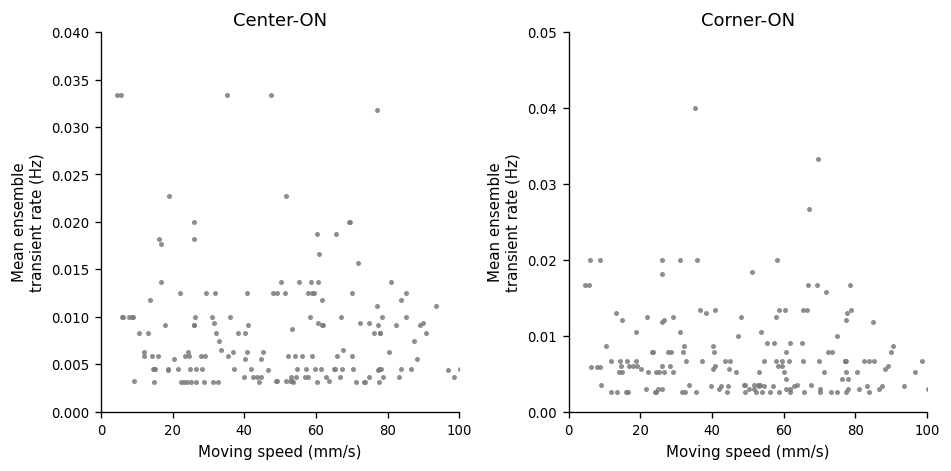

S3A: 178 intervals from 16 mice.


In [2]:
s3a = pd.read_csv(SOURCE / 's3a_transient_rate_vs_speed.csv', keep_default_na=False)
s3a = s3a.loc[:, ~s3a.columns.astype(str).str.startswith('Unnamed:')]
for column in ['speed', 'CenterON_ER', 'CornerON_ER']:
    s3a[column] = pd.to_numeric(s3a[column], errors='coerce')
s3a = s3a.dropna(subset=['speed', 'CenterON_ER', 'CornerON_ER']).copy()

assert len(s3a) == 178, f'Expected 178 plotted intervals, found {len(s3a)}.'
assert s3a['mouse'].nunique() == 16, f"Expected 16 mice, found {s3a['mouse'].nunique()}."

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
panel_specs = [
    ('CenterON_ER', 'Center-ON', (0, 0.04)),
    ('CornerON_ER', 'Corner-ON', (0, 0.05)),
]
for ax, (rate_column, title, ylim) in zip(axes, panel_specs):
    ax.scatter(s3a['speed'], s3a[rate_column], s=9, color='0.48', alpha=0.85, linewidth=0)
    ax.set_title(title, pad=4)
    ax.set_xlabel('Moving speed (mm/s)')
    ax.set_ylabel('Mean ensemble\ntransient rate (Hz)')
    ax.set_xlim(0, 100)
    ax.set_ylim(*ylim)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'fig_s3a_speed_vs_transient_rate.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f"S3A: {len(s3a)} intervals from {s3a['mouse'].nunique()} mice.")